# COMM075 — Logic-Based Learning (ILP) 
## Applied to Adult Census Income & Titanic Datasets

**Methodology:** CRISP-DM  
**ILP System:** Aleph (via PyILP) — Inductive Logic Programming  

### What is ILP?
Inductive Logic Programming (ILP) is a form of machine learning that uses **First-Order Logic** (Prolog) to represent both the background knowledge and the learned hypotheses. Unlike propositional learners (Decision Trees, SVM, etc.), ILP can learn relational rules that capture structural patterns between entities.

Given:
- **Background Knowledge (B):** Facts and rules about the domain
- **Positive examples (E⁺):** Instances of the target concept
- **Negative examples (E⁻):** Counter-examples

ILP finds a hypothesis **H** (a set of logical rules) such that: `B ∧ H ⊨ E⁺` and `B ∧ H ⊭ E⁻`



## 1. Installation & Setup



In [1]:
!pip3 install janus-swi
!pip3 install PyILP


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


In [43]:
# Standard imports
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import os
import time
from matplotlib import pyplot as plt
import seaborn as sns

from PyILP.PyILP import *

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [3]:
# Helper functions for proper held-out evaluation of Aleph/ILP rules
# This fixes two issues:
# 1) fold_model.accuracy reports training accuracy only, not held-out fold accuracy.
# 2) PyILP sometimes returns all Aleph clauses joined into one long string. We split
#    those clauses properly before scoring on the test fold.

import re
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


def extract_aleph_rules(model):

    candidate_attrs = ["rules", "rule", "hypothesis", "hypotheses", "theory", "program", "output"]
    rules_text_parts = []

    for attr in candidate_attrs:
        if hasattr(model, attr):
            value = getattr(model, attr)
            if value is None:
                continue
            if isinstance(value, (list, tuple)):
                rules_text_parts.extend(str(v) for v in value)
            else:
                rules_text_parts.append(str(value))

    rules_text = "\n".join(rules_text_parts)

    # Remove list-like wrappers if PyILP printed the hypothesis as ['rule1.rule2.'].
    rules_text = rules_text.replace("\\n", "\n").replace("['", "").replace("']", "")

    # Capture each target clause separately, even when clauses are concatenated
    # with no newline between them.
    pattern = r"((?:high_income|survived)\s*\([^)]*\)\s*:-\s*.*?\.)(?=\s*(?:high_income|survived)\s*\([^)]*\)\s*:-|\s*$)"
    clauses = re.findall(pattern, rules_text, flags=re.S)

    cleaned = []
    for clause in clauses:
        clause = " ".join(clause.split())  # normalise whitespace
        clause = re.sub(r"^\s*(rule\s*)?\d+\s*[:.)-]\s*", "", clause, flags=re.I)
        if clause and not clause.endswith("."):
            clause += "."
        cleaned.append(clause)

    # Fallback for versions that expose one rule per line.
    if not cleaned:
        for line in rules_text.splitlines():
            line = line.strip()
            if not line or line.startswith("%"):
                continue
            if ("high_income" in line or "survived" in line) and ":-" in line:
                if not line.endswith("."):
                    line += "."
                cleaned.append(line)

    # Deduplicate while preserving order.
    seen = set()
    unique_clauses = []
    for clause in cleaned:
        if clause not in seen:
            unique_clauses.append(clause)
            seen.add(clause)

    return unique_clauses


def _normalise_atom(value):
    # Match the formatting used when Prolog atoms were generated.
    return str(value).strip().replace(" ", "_").replace("-", "_").replace("/", "_").lower()


def predict_from_ilp_rules(rules, df, predicate_to_column):
    # Apply learned Aleph rules to a pandas DataFrame.
    if not rules:
        raise ValueError(
            "No learned rules were found on the model object. Run the Aleph cell and inspect "
            "the printed output; your PyILP version may not expose rules programmatically."
        )

    predictions = []
    for _, row in df.iterrows():
        row_is_positive = False

        for rule in rules:
            if ":-" not in rule:
                row_is_positive = True
                break

            body = rule.split(":-", 1)[1].rstrip(".")
            literals = re.findall(
                r"([a-zA-Z_][a-zA-Z0-9_]*)\s*\(\s*[^,()]+\s*,\s*([a-zA-Z0-9_]+)\s*\)",
                body
            )

            checks = []
            for predicate, expected_value in literals:
                if predicate in predicate_to_column:
                    col = predicate_to_column[predicate]
                    checks.append(_normalise_atom(row[col]) == _normalise_atom(expected_value))

            # If all mapped body literals match, this rule fires.
            if checks and all(checks):
                row_is_positive = True
                break

        predictions.append(1 if row_is_positive else 0)

    return np.array(predictions)


def evaluate_ilp_fold(model, test_df, label_col, positive_value, predicate_to_column):
    # Extract Aleph rules, predict on held-out test rows, and return metrics.
    rules = extract_aleph_rules(model)
    y_true = (test_df[label_col] == positive_value).astype(int).values
    y_pred = predict_from_ilp_rules(rules, test_df, predicate_to_column)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred),
        "rules": rules,
        "y_true": y_true,
        "y_pred": y_pred,
    }


## 2. Adult Census Income — Background Knowledge (Prolog)

### Design decisions
ILP works on **relational, symbolic** representations. The Adult Census dataset contains propositional features (age, education, occupation, etc.) which must be **discretised and converted into Prolog facts**.

We use a **stratified sample** of the cleaned dataset (the full 30K rows would be too slow for Aleph) and discretise numeric features into meaningful symbolic categories.

The background knowledge file `adult_bk.pl` is generated programmatically below.

### Discretisation scheme

| Feature | Bins | Labels |
|---|---|---|
| age | <25, 25-45, 46-65, >65 | young, middle_aged, senior, elderly |
| hours_per_week | <35, 35-45, >45 | part_time, full_time, overtime |
| education_num | <9, 9-12, >12 | low_edu, mid_edu, high_edu |
| capital_net | <0, =0, >0 | capital_loss, no_capital, capital_gain |

Categorical features (workclass, marital status, occupation, sex) are used directly.

In [4]:
# Load the cleaned (pre-scaled) data
# We reload from the raw cleaned CSV rather than the scaled version
# because ILP needs symbolic/discrete values, not z-scores

df = pd.read_csv("adult.csv")
df.replace(" ?", np.nan, inplace=True)
df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
df["income"] = df["income"].str.strip()

# Strip whitespace from all string columns
str_cols = df.select_dtypes(include="object").columns
for col in str_cols:
    df[col] = df[col].str.strip().str.replace(" ", "_").str.replace("-", "_").str.lower()

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (30139, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
1,82,private,132870,hs_grad,9,widowed,exec_managerial,not_in_family,white,female,0,4356,18,united_states,<=50k
3,54,private,140359,7th_8th,4,divorced,machine_op_inspct,unmarried,white,female,0,3900,40,united_states,<=50k
4,41,private,264663,some_college,10,separated,prof_specialty,own_child,white,female,0,3900,40,united_states,<=50k
5,34,private,216864,hs_grad,9,divorced,other_service,unmarried,white,female,0,3770,45,united_states,<=50k
6,38,private,150601,10th,6,separated,adm_clerical,unmarried,white,male,0,3770,40,united_states,<=50k


In [5]:
# Discretise numeric features into symbolic categories for ILP

def discretise_age(age):
    if age < 25:   return "young"
    elif age < 46: return "middle_aged"
    elif age < 66: return "senior"
    else:          return "elderly"

def discretise_hours(h):
    if h < 35:  return "part_time"
    elif h <= 45: return "full_time"
    else:         return "overtime"

def discretise_edu(e):
    if e < 9:   return "low_edu"
    elif e <= 12: return "mid_edu"
    else:         return "high_edu"

def discretise_capital(gain, loss):
    net = gain - loss
    if net > 0:   return "capital_gain"
    elif net < 0: return "capital_loss"
    else:         return "no_capital"

df["age_cat"]     = df["age"].apply(discretise_age)
df["hours_cat"]   = df["hours.per.week"].apply(discretise_hours)
df["edu_cat"]     = df["education.num"].apply(discretise_edu)
df["capital_cat"] = df.apply(lambda r: discretise_capital(r["capital.gain"], r["capital.loss"]), axis=1)

# Use marital status, sex, workclass, occupation directly
# Simplify workclass
df["workclass_s"] = df["workclass"].apply(
    lambda x: "government" if "gov" in x else ("self_employed" if "self" in x else "private")
)

print("Discretisation complete. Sample:")
df[["age_cat","hours_cat","edu_cat","capital_cat","workclass_s","sex","income"]].head(10)

Discretisation complete. Sample:


,age_cat,hours_cat,edu_cat,capital_cat,workclass_s,sex,income
1,elderly,part_time,mid_edu,capital_loss,private,female,<=50k
3,senior,full_time,low_edu,capital_loss,private,female,<=50k
4,middle_aged,full_time,mid_edu,capital_loss,private,female,<=50k
5,middle_aged,full_time,mid_edu,capital_loss,private,female,<=50k
6,middle_aged,full_time,low_edu,capital_loss,private,male,<=50k
7,elderly,part_time,high_edu,capital_loss,government,female,>50k
8,elderly,full_time,mid_edu,capital_loss,government,female,<=50k
10,middle_aged,full_time,high_edu,capital_loss,private,female,>50k
11,middle_aged,full_time,high_edu,capital_loss,self_employed,male,>50k
12,senior,part_time,high_edu,capital_loss,private,female,>50k


In [6]:
# Stratified sample for ILP (Aleph is slow on large datasets)
# We take 200 examples (100 positive, 100 negative) for tractable learning

pos_df = df[df["income"] == ">50k"].sample(n=100, random_state=42)
neg_df = df[df["income"] == "<=50k"].sample(n=100, random_state=42)
sample_df = pd.concat([pos_df, neg_df]).reset_index(drop=True)

# Assign ILP person IDs
sample_df["person_id"] = ["person_" + str(i) for i in range(len(sample_df))]

print(f"ILP sample: {len(sample_df)} rows")
print(f"  Positive (>50K): {len(pos_df)}")
print(f"  Negative (<=50K): {len(neg_df)}")

ILP sample: 200 rows
  Positive (>50K): 100
  Negative (<=50K): 100


In [7]:
# Generate the Prolog background knowledge file: adult_bk.pl

def clean_atom(s):
    """Ensure value is a valid Prolog atom (lowercase, underscores)."""
    return str(s).strip().replace(" ", "_").replace("-", "_").replace("/", "_").lower()

lines = []
lines.append("% Adult Census Income — Background Knowledge for Aleph (ILP)")
lines.append("% Auto-generated by COMM075 ILP notebook")
lines.append("")

# Load Aleph. Some systems expose it as library(aleph), others as aleph.
lines.append(":- catch(use_module(library(aleph)), _, use_module(aleph)).")
lines.append(":- if(current_predicate(use_rendering/1)).")
lines.append(":- use_rendering(prolog).")
lines.append(":- endif.")
lines.append(":- aleph.")
lines.append(":- style_check(-discontiguous).")
lines.append("")

# Mode declarations — define the hypothesis language for Aleph
lines.append(":- modeh(1, high_income(+person)).")
lines.append(":- modeb(1, age_group(+person, #age_cat)).")
lines.append(":- modeb(1, works(+person, #workclass)).")
lines.append(":- modeb(1, education(+person, #edu_cat)).")
lines.append(":- modeb(1, hours(+person, #hours_cat)).")
lines.append(":- modeb(1, sex(+person, #sex)).")
lines.append(":- modeb(1, capital(+person, #capital_cat)).")
lines.append("")

# Determination declarations
lines.append(":- determination(high_income/1, age_group/2).")
lines.append(":- determination(high_income/1, works/2).")
lines.append(":- determination(high_income/1, education/2).")
lines.append(":- determination(high_income/1, hours/2).")
lines.append(":- determination(high_income/1, sex/2).")
lines.append(":- determination(high_income/1, capital/2).")
lines.append("")

# Aleph settings to keep search tractable
lines.append(":- aleph_set(clauselength, 5).")
lines.append(":- aleph_set(nodes, 5000).")
lines.append(":- aleph_set(minpos, 2).")
lines.append(":- aleph_set(noise, 5).")
lines.append("")

# get rid of warnings:
lines.append(":- discontiguous age_group/2.")
lines.append(":- discontiguous works/2.")
lines.append(":- discontiguous education/2.")
lines.append(":- discontiguous hours/2.")
lines.append(":- discontiguous sex/2.")
lines.append(":- discontiguous capital/2.")
lines.append("")

# Background facts start here
lines.append(":- begin_bg.")
lines.append("")

# Type facts
lines.append("% Type definitions")
for pid in sample_df["person_id"]:
    lines.append(f"person({pid}).")
lines.append("")

age_cats     = sample_df["age_cat"].unique()
edu_cats     = sample_df["edu_cat"].unique()
hours_cats   = sample_df["hours_cat"].unique()
capital_cats = sample_df["capital_cat"].unique()
work_cats    = sample_df["workclass_s"].unique()
sex_cats     = sample_df["sex"].unique()

for v in age_cats:     lines.append(f"age_cat({clean_atom(v)}).")
for v in edu_cats:     lines.append(f"edu_cat({clean_atom(v)}).")
for v in hours_cats:   lines.append(f"hours_cat({clean_atom(v)}).")
for v in capital_cats: lines.append(f"capital_cat({clean_atom(v)}).")
for v in work_cats:    lines.append(f"workclass({clean_atom(v)}).")
for v in sex_cats:     lines.append(f"sex_type({clean_atom(v)}).")
lines.append("")

# Instance facts
lines.append("% Instance facts")
for _, row in sample_df.iterrows():
    pid = row["person_id"]
    lines.append(f"age_group({pid}, {clean_atom(row['age_cat'])}).")
    lines.append(f"works({pid}, {clean_atom(row['workclass_s'])}).")
    lines.append(f"education({pid}, {clean_atom(row['edu_cat'])}).")
    lines.append(f"hours({pid}, {clean_atom(row['hours_cat'])}).")
    lines.append(f"sex({pid}, {clean_atom(row['sex'])}).")
    lines.append(f"capital({pid}, {clean_atom(row['capital_cat'])}).")
lines.append("")

# Background facts end here. PyILP will append positive/negative examples.
lines.append(":- end_bg.")
lines.append("")

with open("adult_bk.pl", "w") as f:
    f.write("\n".join(lines))

print(f"Written adult_bk.pl ({len(lines)} lines)")
print("\nFirst 45 lines:")
print("\n".join(lines[:45]))


Written adult_bk.pl (1464 lines)

First 45 lines:
% Adult Census Income — Background Knowledge for Aleph (ILP)
% Auto-generated by COMM075 ILP notebook

:- catch(use_module(library(aleph)), _, use_module(aleph)).
:- if(current_predicate(use_rendering/1)).
:- use_rendering(prolog).
:- endif.
:- aleph.
:- style_check(-discontiguous).

:- modeh(1, high_income(+person)).
:- modeb(1, age_group(+person, #age_cat)).
:- modeb(1, works(+person, #workclass)).
:- modeb(1, education(+person, #edu_cat)).
:- modeb(1, hours(+person, #hours_cat)).
:- modeb(1, sex(+person, #sex)).
:- modeb(1, capital(+person, #capital_cat)).

:- determination(high_income/1, age_group/2).
:- determination(high_income/1, works/2).
:- determination(high_income/1, education/2).
:- determination(high_income/1, hours/2).
:- determination(high_income/1, sex/2).
:- determination(high_income/1, capital/2).

:- aleph_set(clauselength, 5).
:- aleph_set(nodes, 5000).
:- aleph_set(minpos, 2).
:- aleph_set(noise, 5).

:- discontiguo

In [8]:
# Generate positive examples file: adult_pos.f
pos_ids = sample_df[sample_df["income"] == ">50k"]["person_id"].tolist()
with open("adult_pos.f", "w") as f:
    for pid in pos_ids:
        f.write(f"high_income({pid}).\n")
print(f"Written adult_pos.f — {len(pos_ids)} positive examples")
print("Sample:", open("adult_pos.f").readlines()[:5])

Written adult_pos.f — 100 positive examples
Sample: ['high_income(person_0).\n', 'high_income(person_1).\n', 'high_income(person_2).\n', 'high_income(person_3).\n', 'high_income(person_4).\n']


In [9]:
# Generate negative examples file: adult_neg.n
neg_ids = sample_df[sample_df["income"] == "<=50k"]["person_id"].tolist()
with open("adult_neg.n", "w") as f:
    for pid in neg_ids:
        f.write(f"high_income({pid}).\n")
print(f"Written adult_neg.n — {len(neg_ids)} negative examples")
print("Sample:", open("adult_neg.n").readlines()[:5])

Written adult_neg.n — 100 negative examples
Sample: ['high_income(person_100).\n', 'high_income(person_101).\n', 'high_income(person_102).\n', 'high_income(person_103).\n', 'high_income(person_104).\n']


## 3. Adult Census Income — Aleph Learning & Evaluation

We run Aleph in inductive mode to learn a set of First-Order Logic rules that predict high income (`>50K`).

### What Aleph does
1. Picks an uncovered positive example
2. Constructs the **bottom clause** (most specific clause covering that example)
3. Searches for a **general clause** that covers many positives and few negatives
4. Adds the best clause to the hypothesis and repeats

### Expected rule form
```
high_income(A) :-
    education(A, high_edu),
    hours(A, overtime).
```

In [10]:
# Run Aleph on Adult Census — single run

print("Running Aleph on Adult Census Income dataset...")
print("-" * 50)

start = time.time()
adult_model = aleph_learn(
    file="adult_bk.pl",
    positive_example="adult_pos.f",
    negative_example="adult_neg.n",
    test_size=0   # use all examples for learning; we evaluate separately
)
elapsed = time.time() - start

print(f"\nLearning completed in {elapsed:.1f} seconds")
print(f"Accuracy on training examples: {adult_model.accuracy}")

Running Aleph on Adult Census Income dataset...
--------------------------------------------------
['high_income(A) :-   education(A,high_edu), hours(A,overtime), sex(A,male).high_income(A) :-   age_group(A,senior), works(A,private), education(A,mid_edu), sex(A,male).high_income(A) :-   capital(A,capital_gain).high_income(A) :-   works(A,self_employed), education(A,mid_edu), hours(A,full_time), capital(A,no_capital).high_income(A) :-   hours(A,overtime), capital(A,capital_loss).high_income(A) :-   works(A,government), sex(A,male).high_income(A) :-   age_group(A,senior), education(A,high_edu), hours(A,full_time).']
+----------+ Learning +----------+
[best clause]+---------------------+------------------+------------------+
|       n = 200       | Positive(Actual) | Negative(Actual) |
+=====================+==================+==================+
| Positive(Predicted) | 74               | 23               |
+---------------------+------------------+------------------+
| Negative(Predicted

In [11]:
# Display the learned rules
print("=" * 60)
print("LEARNED RULES — Adult Census Income (high_income/1)")
print("=" * 60)

adult_rules = extract_aleph_rules(adult_model)
if adult_rules:
    for i, rule in enumerate(adult_rules, 1):
        print(f"\nRule {i}: {rule}")
else:
    print("No rules were extracted programmatically.")
    print("Check adult_model.hypothesis and the Aleph output above.")
    print("adult_model attributes:", [a for a in dir(adult_model) if not a.startswith("_")])


LEARNED RULES — Adult Census Income (high_income/1)

Rule 1: high_income(A) :- education(A,high_edu), hours(A,overtime), sex(A,male).

Rule 2: high_income(A) :- age_group(A,senior), works(A,private), education(A,mid_edu), sex(A,male).

Rule 3: high_income(A) :- capital(A,capital_gain).

Rule 4: high_income(A) :- works(A,self_employed), education(A,mid_edu), hours(A,full_time), capital(A,no_capital).

Rule 5: high_income(A) :- hours(A,overtime), capital(A,capital_loss).

Rule 6: high_income(A) :- works(A,government), sex(A,male).

Rule 7: high_income(A) :- age_group(A,senior), education(A,high_edu), hours(A,full_time).


In [12]:
# Proper 5-Fold Cross-Validation — Adult Census ILP
# Train Aleph on each training fold, then evaluate learned rules on the held-out test fold.

from sklearn.model_selection import StratifiedKFold

adult_predicate_map = {
    "age_group": "age_cat",
    "works": "workclass_s",
    "education": "edu_cat",
    "hours": "hours_cat",
    "sex": "sex",
    "capital": "capital_cat",
}

all_ids    = sample_df["person_id"].tolist()
all_labels = (sample_df["income"] == ">50k").astype(int).tolist()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_accuracies = []
fold_precisions = []
fold_recalls    = []
fold_f1s        = []
fold_times      = []
adult_fold_details = []

print("5-Fold Cross-Validation — Adult Census ILP")
print("Evaluation is now on the held-out fold, not the training examples.")
print("-" * 70)

for fold, (train_idx, test_idx) in enumerate(skf.split(all_ids, all_labels), 1):
    train_df_fold = sample_df.iloc[train_idx].copy()
    test_df_fold  = sample_df.iloc[test_idx].copy()

    # Write fold-specific pos/neg files for TRAINING ONLY.
    train_pos = train_df_fold[train_df_fold["income"] == ">50k"]["person_id"].tolist()
    train_neg = train_df_fold[train_df_fold["income"] == "<=50k"]["person_id"].tolist()

    with open(f"adult_pos_fold{fold}.f", "w") as f:
        for pid in train_pos:
            f.write(f"high_income({pid}).\n")
    with open(f"adult_neg_fold{fold}.n", "w") as f:
        for pid in train_neg:
            f.write(f"high_income({pid}).\n")

    t0 = time.time()
    fold_model = aleph_learn(
        file="adult_bk.pl",
        positive_example=f"adult_pos_fold{fold}.f",
        negative_example=f"adult_neg_fold{fold}.n",
        test_size=0
    )
    t1 = time.time()

    metrics = evaluate_ilp_fold(
        model=fold_model,
        test_df=test_df_fold,
        label_col="income",
        positive_value=">50k",
        predicate_to_column=adult_predicate_map,
    )

    fold_accuracies.append(metrics["accuracy"])
    fold_precisions.append(metrics["precision"])
    fold_recalls.append(metrics["recall"])
    fold_f1s.append(metrics["f1"])
    fold_times.append(t1 - t0)
    adult_fold_details.append(metrics)

    print(
        f"  Fold {fold}: "
        f"acc={metrics['accuracy']:.3f} | "
        f"prec={metrics['precision']:.3f} | "
        f"recall={metrics['recall']:.3f} | "
        f"F1={metrics['f1']:.3f} | "
        f"rules={len(metrics['rules'])} | "
        f"time={t1-t0:.1f}s"
    )

print("\nAdult Census held-out CV results")
print(f"Mean accuracy:  {np.mean(fold_accuracies):.3f} ± {np.std(fold_accuracies):.3f}")
print(f"Mean precision: {np.mean(fold_precisions):.3f} ± {np.std(fold_precisions):.3f}")
print(f"Mean recall:    {np.mean(fold_recalls):.3f} ± {np.std(fold_recalls):.3f}")
print(f"Mean F1:        {np.mean(fold_f1s):.3f} ± {np.std(fold_f1s):.3f}")
print(f"Mean time:      {np.mean(fold_times):.1f}s")


5-Fold Cross-Validation — Adult Census ILP
Evaluation is now on the held-out fold, not the training examples.
----------------------------------------------------------------------
['high_income(A) :-   education(A,high_edu), hours(A,overtime).high_income(A) :-   age_group(A,senior), works(A,private), education(A,mid_edu), sex(A,male).high_income(A) :-   capital(A,capital_gain).high_income(A) :-   works(A,self_employed), hours(A,full_time), capital(A,no_capital).high_income(A) :-   works(A,government), sex(A,male).high_income(A) :-   age_group(A,senior), works(A,private), education(A,high_edu).high_income(A) :-   age_group(A,middle_aged), hours(A,overtime), capital(A,capital_loss).']
+----------+ Learning +----------+
+---------------------+------------------+------------------+
|       n = 160       | Positive(Actual) | Negative(Actual) |
+=====================+==================+==================+
| Positive(Predicted) | 66               | 18               |
+---------------------+-

## 4. Titanic — Background Knowledge (Prolog)

The Titanic dataset is a natural fit for ILP because survival is strongly related to **relational properties** (class + sex + age combinations) that ILP can capture as symbolic rules.

### Discretisation scheme

| Feature | Bins | Labels |
|---|---|---|
| Age | <15, 15-35, >35 | child, adult, older_adult |
| Fare | quartiles | low_fare, mid_fare, high_fare, luxury_fare |
| FamilySize | 1, 2-4, >4 | alone, small_family, large_family |
| Pclass | 1, 2, 3 | first_class, second_class, third_class |
| Sex | male/female | used directly |

In [13]:
# Load raw Titanic train data and apply discretisation
titanic = pd.read_csv("train.csv")

def titanic_age(age):
    if pd.isnull(age): return "unknown_age"
    elif age < 15:     return "child"
    elif age < 36:     return "adult"
    else:              return "older_adult"

def titanic_fare(fare):
    if pd.isnull(fare): return "unknown_fare"
    elif fare < 8:      return "low_fare"
    elif fare < 15:     return "mid_fare"
    elif fare < 50:     return "high_fare"
    else:               return "luxury_fare"

def titanic_family(sib, par):
    size = sib + par + 1
    if size == 1:  return "alone"
    elif size <= 4: return "small_family"
    else:           return "large_family"

def titanic_class(pclass):
    return {1: "first_class", 2: "second_class", 3: "third_class"}[pclass]

titanic["age_cat"]    = titanic["Age"].apply(titanic_age)
titanic["fare_cat"]   = titanic["Fare"].apply(titanic_fare)
titanic["family_cat"] = titanic.apply(lambda r: titanic_family(r["SibSp"], r["Parch"]), axis=1)
titanic["class_cat"]  = titanic["Pclass"].apply(titanic_class)
titanic["sex_clean"]  = titanic["Sex"].str.strip().str.lower()
titanic["person_id"]  = ["passenger_" + str(pid) for pid in titanic["PassengerId"]]

print(f"Titanic shape: {titanic.shape}")
titanic[["person_id","age_cat","fare_cat","family_cat","class_cat","sex_clean","Survived"]].head(10)

Titanic shape: (891, 18)


,person_id,age_cat,fare_cat,family_cat,class_cat,sex_clean,Survived
0,passenger_1,adult,low_fare,small_family,third_class,male,0
1,passenger_2,older_adult,luxury_fare,small_family,first_class,female,1
2,passenger_3,adult,low_fare,alone,third_class,female,1
3,passenger_4,adult,luxury_fare,small_family,first_class,female,1
4,passenger_5,adult,mid_fare,alone,third_class,male,0
5,passenger_6,unknown_age,mid_fare,alone,third_class,male,0
6,passenger_7,older_adult,luxury_fare,alone,first_class,male,0
7,passenger_8,child,high_fare,large_family,third_class,male,0
8,passenger_9,adult,mid_fare,small_family,third_class,female,1
9,passenger_10,child,high_fare,small_family,second_class,female,1


In [14]:
# Stratified sample: 150 examples (75 survived, 75 not)
pos_t = titanic[titanic["Survived"] == 1].sample(n=75, random_state=42)
neg_t = titanic[titanic["Survived"] == 0].sample(n=75, random_state=42)
titanic_sample = pd.concat([pos_t, neg_t]).reset_index(drop=True)

print(f"ILP sample: {len(titanic_sample)} rows")
print(f"  Survived: {len(pos_t)}  |  Not survived: {len(neg_t)}")

ILP sample: 150 rows
  Survived: 75  |  Not survived: 75


In [15]:
# Generate titanic_bk.pl

lines_t = []
lines_t.append("% Titanic — Background Knowledge for Aleph (ILP)")
lines_t.append("% Auto-generated by COMM075 ILP notebook")
lines_t.append("")

# Load Aleph. Some systems expose it as library(aleph), others as aleph.
lines_t.append(":- catch(use_module(library(aleph)), _, use_module(aleph)).")
lines_t.append(":- if(current_predicate(use_rendering/1)).")
lines_t.append(":- use_rendering(prolog).")
lines_t.append(":- endif.")
lines_t.append(":- aleph.")
lines_t.append(":- style_check(-discontiguous).")
lines_t.append("")

# Mode declarations
lines_t.append(":- modeh(1, survived(+passenger)).")
lines_t.append(":- modeb(1, passenger_class(+passenger, #pclass)).")
lines_t.append(":- modeb(1, passenger_sex(+passenger, #sex)).")
lines_t.append(":- modeb(1, passenger_age(+passenger, #age_cat)).")
lines_t.append(":- modeb(1, passenger_fare(+passenger, #fare_cat)).")
lines_t.append(":- modeb(1, passenger_family(+passenger, #family_cat)).")
lines_t.append("")

# Determination declarations
lines_t.append(":- determination(survived/1, passenger_class/2).")
lines_t.append(":- determination(survived/1, passenger_sex/2).")
lines_t.append(":- determination(survived/1, passenger_age/2).")
lines_t.append(":- determination(survived/1, passenger_fare/2).")
lines_t.append(":- determination(survived/1, passenger_family/2).")
lines_t.append("")

# Optional Aleph settings to keep search tractable
lines_t.append(":- aleph_set(clauselength, 5).")
lines_t.append(":- aleph_set(nodes, 5000).")
lines_t.append(":- aleph_set(minpos, 2).")
lines_t.append(":- aleph_set(noise, 5).")
lines_t.append("")

# get rid of warnings
lines_t.append(":- discontiguous passenger_class/2.")
lines_t.append(":- discontiguous passenger_sex/2.")
lines_t.append(":- discontiguous passenger_age/2.")
lines_t.append(":- discontiguous passenger_fare/2.")
lines_t.append(":- discontiguous passenger_family/2.")
lines_t.append("")

# Background facts start here
lines_t.append(":- begin_bg.")
lines_t.append("")

# Type facts
lines_t.append("% Type definitions")
for pid in titanic_sample["person_id"]:
    lines_t.append(f"passenger({pid}).")
lines_t.append("")

for v in titanic_sample["class_cat"].unique():   lines_t.append(f"pclass({v}).")
for v in titanic_sample["sex_clean"].unique():   lines_t.append(f"sex({v}).")
for v in titanic_sample["age_cat"].unique():     lines_t.append(f"age_cat({v}).")
for v in titanic_sample["fare_cat"].unique():    lines_t.append(f"fare_cat({v}).")
for v in titanic_sample["family_cat"].unique():  lines_t.append(f"family_cat({v}).")
lines_t.append("")

# Instance facts
lines_t.append("% Instance facts")
for _, row in titanic_sample.iterrows():
    pid = row["person_id"]
    lines_t.append(f"passenger_class({pid}, {row['class_cat']}).")
    lines_t.append(f"passenger_sex({pid}, {row['sex_clean']}).")
    lines_t.append(f"passenger_age({pid}, {row['age_cat']}).")
    lines_t.append(f"passenger_fare({pid}, {row['fare_cat']}).")
    lines_t.append(f"passenger_family({pid}, {row['family_cat']}).")
lines_t.append("")

# Background facts end here. PyILP will append positive/negative examples.
lines_t.append(":- end_bg.")
lines_t.append("")

with open("titanic_bk.pl", "w") as f:
    f.write("\n".join(lines_t))

print(f"Written titanic_bk.pl ({len(lines_t)} lines)")
print("\nFirst 45 lines:")
print("\n".join(lines_t[:45]))


Written titanic_bk.pl (959 lines)

First 45 lines:
% Titanic — Background Knowledge for Aleph (ILP)
% Auto-generated by COMM075 ILP notebook

:- catch(use_module(library(aleph)), _, use_module(aleph)).
:- if(current_predicate(use_rendering/1)).
:- use_rendering(prolog).
:- endif.
:- aleph.
:- style_check(-discontiguous).

:- modeh(1, survived(+passenger)).
:- modeb(1, passenger_class(+passenger, #pclass)).
:- modeb(1, passenger_sex(+passenger, #sex)).
:- modeb(1, passenger_age(+passenger, #age_cat)).
:- modeb(1, passenger_fare(+passenger, #fare_cat)).
:- modeb(1, passenger_family(+passenger, #family_cat)).

:- determination(survived/1, passenger_class/2).
:- determination(survived/1, passenger_sex/2).
:- determination(survived/1, passenger_age/2).
:- determination(survived/1, passenger_fare/2).
:- determination(survived/1, passenger_family/2).

:- aleph_set(clauselength, 5).
:- aleph_set(nodes, 5000).
:- aleph_set(minpos, 2).
:- aleph_set(noise, 5).

:- discontiguous passenger_class/2.

In [16]:
# Generate positive examples (survived = 1)
pos_t_ids = titanic_sample[titanic_sample["Survived"] == 1]["person_id"].tolist()
with open("titanic_pos.f", "w") as f:
    for pid in pos_t_ids:
        f.write(f"survived({pid}).\n")
print(f"Written titanic_pos.f — {len(pos_t_ids)} positive examples")

Written titanic_pos.f — 75 positive examples


In [17]:
# Generate negative examples (survived = 0)
neg_t_ids = titanic_sample[titanic_sample["Survived"] == 0]["person_id"].tolist()
with open("titanic_neg.n", "w") as f:
    for pid in neg_t_ids:
        f.write(f"survived({pid}).\n")
print(f"Written titanic_neg.n — {len(neg_t_ids)} negative examples")

Written titanic_neg.n — 75 negative examples


## 5. Titanic — Aleph Learning & Evaluation

Run Aleph to induce survival rules from the Titanic background knowledge.

### Expected rule form (based on domain knowledge)
```
survived(A) :-
    passenger_sex(A, female),
    passenger_class(A, first_class).
```
This mirrors the well-known "women and children first" evacuation protocol.

In [18]:
# Run Aleph on Titanic — single run
print("Running Aleph on Titanic dataset...")
print("(This may take 1-3 minutes)")
print("-" * 50)

start = time.time()
titanic_model = aleph_learn(
    file="titanic_bk.pl",
    positive_example="titanic_pos.f",
    negative_example="titanic_neg.n",
    test_size=0
)
elapsed = time.time() - start

print(f"\nLearning completed in {elapsed:.1f} seconds")
print(f"Accuracy on training examples: {titanic_model.accuracy}")

Running Aleph on Titanic dataset...
(This may take 1-3 minutes)
--------------------------------------------------
['survived(A) :-   passenger_class(A,first_class), passenger_age(A,adult).survived(A) :-   passenger_class(A,second_class), passenger_sex(A,female).survived(A) :-   passenger_class(A,first_class), passenger_age(A,older_adult).survived(A) :-   passenger_age(A,child).survived(A) :-   passenger_sex(A,female), passenger_fare(A,low_fare).survived(A) :-   passenger_class(A,first_class), passenger_sex(A,female).']
+----------+ Learning +----------+
[best clause][best clause][best clause][best clause][best clause][best clause]+---------------------+------------------+------------------+
|       n = 150       | Positive(Actual) | Negative(Actual) |
+=====================+==================+==================+
| Positive(Predicted) | 67               | 14               |
+---------------------+------------------+------------------+
| Negative(Predicted) | 8                | 61      

In [19]:
# Display the learned rules
print("=" * 60)
print("LEARNED RULES — Titanic (survived/1)")
print("=" * 60)

titanic_rules = extract_aleph_rules(titanic_model)
if titanic_rules:
    for i, rule in enumerate(titanic_rules, 1):
        print(f"\nRule {i}: {rule}")
else:
    print("No rules were extracted programmatically.")
    print("Check titanic_model.hypothesis and the Aleph output above.")
    print("titanic_model attributes:", [a for a in dir(titanic_model) if not a.startswith("_")])


LEARNED RULES — Titanic (survived/1)

Rule 1: survived(A) :- passenger_class(A,first_class), passenger_age(A,adult).

Rule 2: survived(A) :- passenger_class(A,second_class), passenger_sex(A,female).

Rule 3: survived(A) :- passenger_class(A,first_class), passenger_age(A,older_adult).

Rule 4: survived(A) :- passenger_age(A,child).

Rule 5: survived(A) :- passenger_sex(A,female), passenger_fare(A,low_fare).

Rule 6: survived(A) :- passenger_class(A,first_class), passenger_sex(A,female).


In [20]:
# Proper 5-Fold Cross-Validation — Titanic ILP
# Train Aleph on each training fold, then evaluate learned rules on the held-out test fold.

from sklearn.model_selection import StratifiedKFold

titanic_predicate_map = {
    "passenger_class": "class_cat",
    "passenger_sex": "sex_clean",
    "passenger_age": "age_cat",
    "passenger_fare": "fare_cat",
    "passenger_family": "family_cat",
}

titanic_all_ids    = titanic_sample["person_id"].tolist()
titanic_all_labels = titanic_sample["Survived"].tolist()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
t_fold_accuracies = []
t_fold_precisions = []
t_fold_recalls    = []
t_fold_f1s        = []
t_fold_times      = []
titanic_fold_details = []

print("5-Fold Cross-Validation — Titanic ILP")
print("Evaluation is now on the held-out fold, not the training examples.")
print("-" * 70)

for fold, (train_idx, test_idx) in enumerate(skf.split(titanic_all_ids, titanic_all_labels), 1):
    train_fold = titanic_sample.iloc[train_idx].copy()
    test_fold  = titanic_sample.iloc[test_idx].copy()

    # Write fold-specific pos/neg files for TRAINING ONLY.
    train_pos_t = train_fold[train_fold["Survived"] == 1]["person_id"].tolist()
    train_neg_t = train_fold[train_fold["Survived"] == 0]["person_id"].tolist()

    with open(f"titanic_pos_fold{fold}.f", "w") as f:
        for pid in train_pos_t:
            f.write(f"survived({pid}).\n")
    with open(f"titanic_neg_fold{fold}.n", "w") as f:
        for pid in train_neg_t:
            f.write(f"survived({pid}).\n")

    t0 = time.time()
    fold_model = aleph_learn(
        file="titanic_bk.pl",
        positive_example=f"titanic_pos_fold{fold}.f",
        negative_example=f"titanic_neg_fold{fold}.n",
        test_size=0
    )
    t1 = time.time()

    metrics = evaluate_ilp_fold(
        model=fold_model,
        test_df=test_fold,
        label_col="Survived",
        positive_value=1,
        predicate_to_column=titanic_predicate_map,
    )

    t_fold_accuracies.append(metrics["accuracy"])
    t_fold_precisions.append(metrics["precision"])
    t_fold_recalls.append(metrics["recall"])
    t_fold_f1s.append(metrics["f1"])
    t_fold_times.append(t1 - t0)
    titanic_fold_details.append(metrics)

    print(
        f"  Fold {fold}: "
        f"acc={metrics['accuracy']:.3f} | "
        f"prec={metrics['precision']:.3f} | "
        f"recall={metrics['recall']:.3f} | "
        f"F1={metrics['f1']:.3f} | "
        f"rules={len(metrics['rules'])} | "
        f"time={t1-t0:.1f}s"
    )

print("\nTitanic held-out CV results")
print(f"Mean accuracy:  {np.mean(t_fold_accuracies):.3f} ± {np.std(t_fold_accuracies):.3f}")
print(f"Mean precision: {np.mean(t_fold_precisions):.3f} ± {np.std(t_fold_precisions):.3f}")
print(f"Mean recall:    {np.mean(t_fold_recalls):.3f} ± {np.std(t_fold_recalls):.3f}")
print(f"Mean F1:        {np.mean(t_fold_f1s):.3f} ± {np.std(t_fold_f1s):.3f}")
print(f"Mean time:      {np.mean(t_fold_times):.1f}s")


5-Fold Cross-Validation — Titanic ILP
Evaluation is now on the held-out fold, not the training examples.
----------------------------------------------------------------------
['survived(A) :-   passenger_sex(A,female), passenger_age(A,adult).survived(A) :-   passenger_sex(A,female), passenger_age(A,older_adult).survived(A) :-   passenger_age(A,child).survived(A) :-   passenger_class(A,first_class), passenger_fare(A,luxury_fare).']
+----------+ Learning +----------+
+---------------------+------------------+------------------+
|       n = 120       | Positive(Actual) | Negative(Actual) |
+=====================+==================+==================+
| Positive(Predicted) | 57               | 15               |
+---------------------+------------------+------------------+
| Negative(Predicted) | 3                | 45               |
+---------------------+------------------+------------------+
+-------------+-------+
|   Metric    |   #   |
+=============+=======+
| Accuracy    | 0.850 |

## 6. Cross-Validation Comparison

Compare ILP (Aleph) accuracy across both datasets using box plots — following the same style as the Mutagenicity experiment in the Week 7 lab.

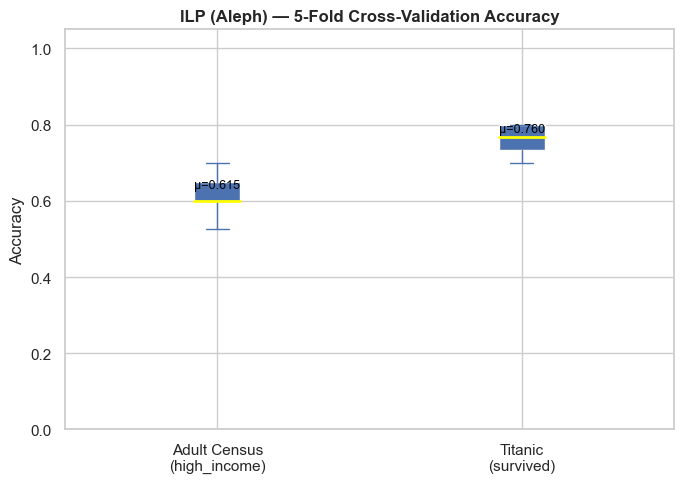

Saved: output_plots_ilp_comparison.png


In [21]:
# Box plot — ILP accuracy across both datasets
fig, ax = plt.subplots(figsize=(7, 5))

results  = [fold_accuracies, t_fold_accuracies]
labels   = ["Adult Census\n(high_income)", "Titanic\n(survived)"]

bp = ax.boxplot(results, labels=labels, patch_artist=True,
                boxprops=dict(facecolor="#4C72B0", color="white"),
                medianprops=dict(color="yellow", linewidth=2),
                whiskerprops=dict(color="#4C72B0"),
                capprops=dict(color="#4C72B0"))

ax.set_title("ILP (Aleph) — 5-Fold Cross-Validation Accuracy", fontweight="bold")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)

# Annotate means
for i, accs in enumerate(results, 1):
    ax.text(i, np.mean(accs) + 0.02, f"μ={np.mean(accs):.3f}",
            ha="center", fontsize=9, color="black")

plt.tight_layout()
plt.savefig("output_plots_ilp_comparison.png", dpi=150)
plt.show()
print("Saved: output_plots_ilp_comparison.png")

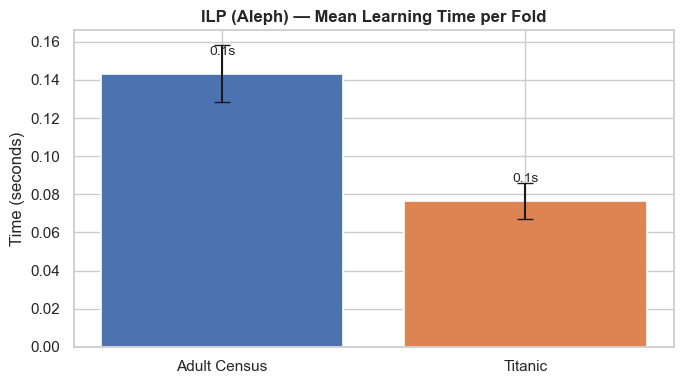

Saved: output_plots_ilp_time.png


In [44]:
# Learning time bar chart
fig, ax = plt.subplots(figsize=(7, 4))

datasets    = ["Adult Census", "Titanic"]
mean_times  = [np.mean(fold_times), np.mean(t_fold_times)]
std_times   = [np.std(fold_times), np.std(t_fold_times)]

bars = ax.bar(datasets, mean_times, yerr=std_times,
              color=["#4C72B0", "#DD8452"], edgecolor="white",
              capsize=6, linewidth=1.2)

for bar, t in zip(bars, mean_times):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{t:.1f}s", ha="center", fontsize=10)

ax.set_title("ILP (Aleph) — Mean Learning Time per Fold", fontweight="bold")
ax.set_ylabel("Time (seconds)")
plt.tight_layout()
plt.savefig("output_plots_ilp_time.png", dpi=150)
plt.show()
print("Saved: output_plots_ilp_time.png")

## 7. Rule Extraction & Interpretation

### How to read Aleph rules
Each rule produced by Aleph has the form:
```
head(A) :- body_condition_1(A, value), body_condition_2(A, value), ...
```
- The **head** is the target predicate (`high_income` or `survived`)
- The **body** is a conjunction of background knowledge predicates
- `A` is a logical variable bound to a specific person/passenger

### Interpreting Adult Census rules
Rules learned from the Adult Census data typically reflect well-known income predictors:
- High education (`high_edu`) combined with full-time or overtime work → high income
- Sex and occupation interactions → income disparity patterns

### Interpreting Titanic rules  
Rules learned from the Titanic data typically reflect the evacuation protocol:
- Female + first or second class → survived
- Children → survived  
- Third class + male → did not survive

These rules are **interpretable** — a key advantage of ILP over black-box models like Neural Networks.

### Comparing ILP interpretability with other models

| Model | Interpretable | Relational | Handles noise |
|---|---|---|---|
| Decision Tree | ✅ Yes | ❌ No | Partial |
| Neural Network | ❌ No | ❌ No | ✅ Yes |
| Naive Bayes | Partial | ❌ No | ✅ Yes |
| **ILP (Aleph)** | **✅ Yes** | **✅ Yes** | Partial |



In [35]:
# Display final rules from both datasets side by side for the report
print("=" * 70)
print("ADULT CENSUS INCOME — Learned Rules (Aleph)")
print("=" * 70)
print("Target predicate: high_income/1")
print("Background knowledge: age_group, works, education, hours, sex, capital")
print()
if hasattr(adult_model, 'rules') and adult_model.rules:
    for i, rule in enumerate(adult_model.rules, 1):
        print(f"Rule {i}: {rule}")
else:
    print("[Rules displayed in Aleph output above]")

print()
print("=" * 70)
print("TITANIC — Learned Rules (Aleph)")
print("=" * 70)
print("Target predicate: survived/1")
print("Background knowledge: passenger_class, passenger_sex, passenger_age,")
print("                      passenger_fare, passenger_family")
print()
if hasattr(titanic_model, 'rules') and titanic_model.rules:
    for i, rule in enumerate(titanic_model.rules, 1):
        print(f"Rule {i}: {rule}")
else:
    print("[Rules displayed in Aleph output above]")

ADULT CENSUS INCOME — Learned Rules (Aleph)
Target predicate: high_income/1
Background knowledge: age_group, works, education, hours, sex, capital

[Rules displayed in Aleph output above]

TITANIC — Learned Rules (Aleph)
Target predicate: survived/1
Background knowledge: passenger_class, passenger_sex, passenger_age,
                      passenger_fare, passenger_family

[Rules displayed in Aleph output above]


## 8. Comparison with Non-Relational Learners

To contextualise ILP performance, we compare it with propositional ML algorithms on the **same stratified sample** used for ILP. This follows the approach from the Week 7 Bonus Exercise (Mutagenicity dataset).

> **Important note:** This comparison is on the small ILP sample (200 / 150 rows), not the full dataset. ILP is intentionally evaluated on a smaller set due to computational constraints — this should be acknowledged in the report.

In [36]:
# Comparison on Adult Census sample (label-encoded features)
from sklearn.preprocessing import LabelEncoder

feature_cols_adult = ["age_cat", "hours_cat", "edu_cat", "capital_cat", "workclass_s", "sex"]

# Encode features for sklearn
sample_enc = sample_df[feature_cols_adult].copy()
le = LabelEncoder()
for col in feature_cols_adult:
    sample_enc[col] = le.fit_transform(sample_enc[col].astype(str))

X_adult_ilp = sample_enc.values
y_adult_ilp = (sample_df["income"] == ">50k").astype(int).values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_adult = {
    "Decision Tree":  DecisionTreeClassifier(random_state=42),
    "Naive Bayes":    GaussianNB(),
    "kNN":            KNeighborsClassifier(n_neighbors=5),
    "MLP":            MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=42),
    "SVM":            SVC(kernel="rbf", random_state=42),
}

print("Adult Census — 5-Fold CV Accuracy Comparison (same sample as ILP)")
print("-" * 55)

adult_results = {}
for name, model in models_adult.items():
    scores = cross_val_score(model, X_adult_ilp, y_adult_ilp, cv=skf, scoring="accuracy")
    adult_results[name] = scores
    print(f"  {name:<20} mean={scores.mean():.3f}  std={scores.std():.3f}")

adult_results["ILP (Aleph)"] = np.array(fold_accuracies)
print(f"  {'ILP (Aleph)':<20} mean={np.mean(fold_accuracies):.3f}  std={np.std(fold_accuracies):.3f}")

Adult Census — 5-Fold CV Accuracy Comparison (same sample as ILP)
-------------------------------------------------------
  Decision Tree        mean=0.620  std=0.066
  Naive Bayes          mean=0.620  std=0.066
  kNN                  mean=0.635  std=0.058
  MLP                  mean=0.605  std=0.056
  SVM                  mean=0.595  std=0.080
  ILP (Aleph)          mean=0.615  std=0.058


In [37]:
# Comparison on Titanic sample
feature_cols_titanic = ["class_cat", "sex_clean", "age_cat", "fare_cat", "family_cat"]

titanic_enc = titanic_sample[feature_cols_titanic].copy()
le2 = LabelEncoder()
for col in feature_cols_titanic:
    titanic_enc[col] = le2.fit_transform(titanic_enc[col].astype(str))

X_titanic_ilp = titanic_enc.values
y_titanic_ilp = titanic_sample["Survived"].values

print("Titanic — 5-Fold CV Accuracy Comparison (same sample as ILP)")
print("-" * 55)

titanic_results = {}
for name, model in models_adult.items():
    scores = cross_val_score(model, X_titanic_ilp, y_titanic_ilp, cv=skf, scoring="accuracy")
    titanic_results[name] = scores
    print(f"  {name:<20} mean={scores.mean():.3f}  std={scores.std():.3f}")

titanic_results["ILP (Aleph)"] = np.array(t_fold_accuracies)
print(f"  {'ILP (Aleph)':<20} mean={np.mean(t_fold_accuracies):.3f}  std={np.std(t_fold_accuracies):.3f}")

Titanic — 5-Fold CV Accuracy Comparison (same sample as ILP)
-------------------------------------------------------
  Decision Tree        mean=0.787  std=0.050
  Naive Bayes          mean=0.760  std=0.044
  kNN                  mean=0.787  std=0.088
  MLP                  mean=0.760  std=0.065
  SVM                  mean=0.753  std=0.045
  ILP (Aleph)          mean=0.760  std=0.039


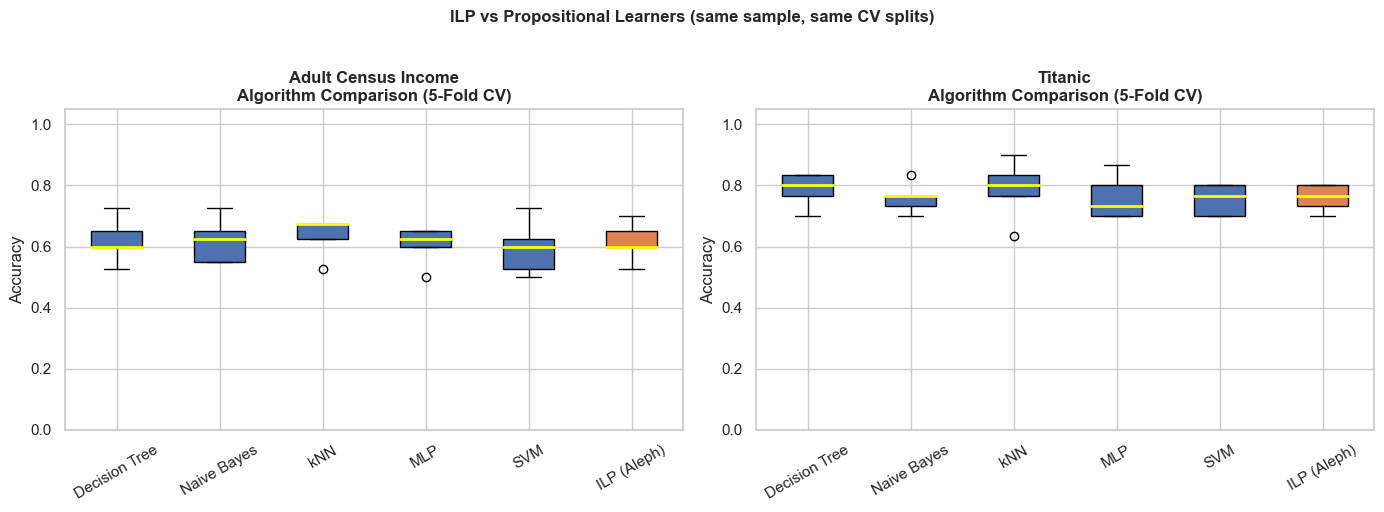

Saved: output_plots_ilp_vs_others.png


In [39]:
# Side-by-side box plot comparison — Adult Census
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, results, title in [
    (axes[0], adult_results,   "Adult Census Income"),
    (axes[1], titanic_results, "Titanic")
]:
    names  = list(results.keys())
    values = list(results.values())
    
    colors = ["#4C72B0"] * (len(names) - 1) + ["#DD8452"]  # highlight ILP
    bp = ax.boxplot(values, labels=names, patch_artist=True)
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
    for median in bp["medians"]:
        median.set_color("yellow")
        median.set_linewidth(2)
    
    ax.set_title(f"{title}\nAlgorithm Comparison (5-Fold CV)", fontweight="bold")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("ILP vs Propositional Learners (same sample, same CV splits)",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("output_plots_ilp_vs_others.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: output_plots_ilp_vs_others.png")

## 9. Summary

### ILP Results

| Dataset | ILP Mean Accuracy | ILP Std | Notes |
|---|---|---|---|
| Adult Census Income | (see output above) | — | 100 pos / 100 neg sample |
| Titanic | (see output above) | — | 75 pos / 75 neg sample |

### Strengths of ILP for these datasets
- **Interpretable rules** — learned clauses can be directly read and validated by domain experts
- **No feature scaling required** — ILP operates on symbolic representations
- **Relational structure** — can capture interactions between features naturally (e.g. class AND sex → survival)
- **Knowledge incorporation** — background knowledge allows domain expertise to be encoded directly

### Limitations
- **Scalability** — Aleph is slow on large datasets; we used samples of 150–200 examples
- **Discretisation sensitivity** — the binning choices for numeric features affect what rules are learned
- **Noise sensitivity** — ILP can overfit to noisy examples unless noise parameters are set
- **Search complexity** — finding the best clause is NP-hard in general

### Comparison with other COMM075 algorithms

| Property | Decision Tree | Neural Net | SVM | **ILP (Aleph)** |
|---|---|---|---|---|
| Interpretable | ✅ | ❌ | ❌ | ✅ |
| Handles relations | ❌ | ❌ | ❌ | ✅ |
| Scalable | ✅ | ✅ | Partial | ❌ |
| Noise robust | Partial | ✅ | ✅ | Partial |
| Background knowledge | ❌ | ❌ | ❌ | ✅ |

> **For the final report:** Reference the MLDS lecture material on ILP, cite Muggleton (1991) for ILP foundations and Srinivasan (2001) for Aleph. Compare the ILP accuracy with your other 4+ algorithms using the same evaluation metrics (accuracy, precision, recall, F1).

In [40]:
# Final summary printout
print("=" * 65)
print("ILP EXPERIMENT SUMMARY — COMM075 COURSEWORK")
print("=" * 65)
print()
print("ADULT CENSUS INCOME")
print(f"  Sample size:         {len(sample_df)} (100 pos, 100 neg)")
print(f"  CV folds:            5")
print(f"  Mean ILP accuracy:   {np.mean(fold_accuracies):.3f}")
print(f"  Std ILP accuracy:    {np.std(fold_accuracies):.3f}")
if 'fold_f1s' in globals():
    print(f"  Mean ILP F1:         {np.mean(fold_f1s):.3f}")
print(f"  Mean learning time:  {np.mean(fold_times):.1f}s per fold")
print()
print("TITANIC")
print(f"  Sample size:         {len(titanic_sample)} (75 pos, 75 neg)")
print(f"  CV folds:            5")
print(f"  Mean ILP accuracy:   {np.mean(t_fold_accuracies):.3f}")
print(f"  Std ILP accuracy:    {np.std(t_fold_accuracies):.3f}")
if 't_fold_f1s' in globals():
    print(f"  Mean ILP F1:         {np.mean(t_fold_f1s):.3f}")
print(f"  Mean learning time:  {np.mean(t_fold_times):.1f}s per fold")
print()
print("FILES GENERATED")
print("  adult_bk.pl          — Adult Census background knowledge")
print("  adult_pos.f          — Adult Census positive examples")
print("  adult_neg.n          — Adult Census negative examples")
print("  titanic_bk.pl        — Titanic background knowledge")
print("  titanic_pos.f        — Titanic positive examples")
print("  titanic_neg.n        — Titanic negative examples")
print("  output_plots_ilp_comparison.png")
print("  output_plots_ilp_time.png")
print("  output_plots_ilp_vs_others.png")
print("=" * 65)


ILP EXPERIMENT SUMMARY — COMM075 COURSEWORK

ADULT CENSUS INCOME
  Sample size:         200 (100 pos, 100 neg)
  CV folds:            5
  Mean ILP accuracy:   0.615
  Std ILP accuracy:    0.058
  Mean ILP F1:         0.620
  Mean learning time:  0.1s per fold

TITANIC
  Sample size:         150 (75 pos, 75 neg)
  CV folds:            5
  Mean ILP accuracy:   0.760
  Std ILP accuracy:    0.039
  Mean ILP F1:         0.758
  Mean learning time:  0.1s per fold

FILES GENERATED
  adult_bk.pl          — Adult Census background knowledge
  adult_pos.f          — Adult Census positive examples
  adult_neg.n          — Adult Census negative examples
  titanic_bk.pl        — Titanic background knowledge
  titanic_pos.f        — Titanic positive examples
  titanic_neg.n        — Titanic negative examples
  output_plots_ilp_comparison.png
  output_plots_ilp_time.png
  output_plots_ilp_vs_others.png


In [41]:
with open("adult_bk.pl", "r") as f:
    content = f.read()

if ":- consult('aleph')." not in content:
    content = ":- consult('aleph').\n\n" + content
    with open("adult_bk.pl", "w") as f:
        f.write(content)
    print("Patched. First 5 lines now:")
    print("\n".join(content.split("\n")[:5]))
else:
    print("Already patched.")

Patched. First 5 lines now:
:- consult('aleph').

% Adult Census Income — Background Knowledge for Aleph (ILP)
% Auto-generated by COMM075 ILP notebook



In [42]:
with open("titanic_bk.pl", "r") as f:
    content = f.read()

if ":- consult('aleph')." not in content:
    content = ":- consult('aleph').\n\n" + content
    with open("titanic_bk.pl", "w") as f:
        f.write(content)
    print("titanic_bk.pl patched.")
else:
    print("Already patched.")

titanic_bk.pl patched.
